# Experiment E — 概念ペアとCue制約の統合検証
Dと同じ75ペア＋5アンカー、700候補、品質フィルタ、中心、最適化予算で旧±0.04/0.03と新±0.06/0.01を比較。CPUのみ、APIなし。


In [1]:
import io,json,time,base64,hashlib,itertools,unicodedata,platform,zipfile
from pathlib import Path
from difflib import SequenceMatcher
import importlib.metadata as im
import numpy as np,pandas as pd,requests,matplotlib.pyplot as plt
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.stats import rankdata,spearmanr
from google.colab import userdata
from IPython.display import display
from tqdm.auto import tqdm
CFG=json.loads("{\"repo\":\"ryouy/GraduationThesis\",\"branch\":\"experiments/concept-pair-selection-v1\",\"run_id\":\"20261126_concept_pair_integrated_E_v1\",\"B_ref\":\"ada2278f06f89a9adc32c4efe2eab083935cfd68\",\"C_ref\":\"6eb730f8dcaf48bfce9d98825b13e41d2a4dbd25\",\"B_root\":\"experiments/2026-11/1126_concept_pair_selection/results/20261126_concept_pair_distance_B_v1/\",\"C_root\":\"experiments/2026-11/1126_concept_pair_selection/results/20261126_concept_pair_distance_C_small_v1/\",\"setting\":\"C\",\"half_width\":0.04,\"min_gap\":0.03,\"styles\":[\"structure\",\"action\",\"situation\",\"function\"],\"seeds\":[11,23,37],\"steps_per_seed\":1200,\"rho_target\":0.3,\"spread_target\":0.05,\"duplicate_threshold\":0.8,\"pools\":[\"old_quality_no_y_name\",\"known_audit_fail_excluded\"],\"primary_pool\":\"old_quality_no_y_name\",\"include_anchors\":true,\"api_calls\":0,\"status\":\"exploratory\"}")
REPO=CFG['repo'];BRANCH=CFG['branch']
DEST='experiments/2026-11/1126_concept_pair_selection/results/'+CFG['run_id']+'/'
BASE='https://api.github.com/repos/'+REPO+'/contents/'
WORK=Path('/content')/CFG['run_id'];WORK.mkdir(exist_ok=True)
TOKEN=userdata.get('GITHUB_RESULTS_TOKEN')
assert TOKEN,'Set Colab Secret GITHUB_RESULTS_TOKEN'
gh=requests.Session();gh.headers.update({'Authorization':'Bearer '+TOKEN,'Accept':'application/vnd.github+json'})
def dump(x):return (json.dumps(x,ensure_ascii=False,sort_keys=True,indent=2,allow_nan=False)+'\n').encode()
def sha(b):return hashlib.sha256(b).hexdigest()
def blob(b):return hashlib.sha1(b'blob '+str(len(b)).encode()+b'\0'+b).hexdigest()
def norm(s):return ' '.join(unicodedata.normalize('NFKC',str(s)).casefold().split())
def boolean(s):
    v=s.astype(str).str.lower();assert v.isin(['true','false']).all()
    return v.eq('true')
def wait_for(r,i):
    wait=max(2**i,2)
    if r.headers.get('Retry-After','').isdigit():wait=max(wait,int(r.headers['Retry-After']))
    if r.headers.get('X-RateLimit-Remaining')=='0' and r.headers.get('X-RateLimit-Reset','').isdigit():wait=max(wait,int(r.headers['X-RateLimit-Reset'])-int(time.time())+3)
    if r.status_code in (403,429):wait=max(wait,60)
    time.sleep(wait)
def read(path,ref=BRANCH):
    for i in range(6):
        try:
            r=gh.get(BASE+path,params={'ref':ref},timeout=120)
            if r.status_code==404:return None
            if r.status_code in (429,500,502,503,504) or (r.status_code==403 and 'rate limit' in r.text.lower()):
                wait_for(r,i);continue
            r.raise_for_status();j=r.json()
            if j.get('encoding')=='base64':b=base64.b64decode(j['content'])
            else:
                r=gh.get(BASE+path,params={'ref':ref},headers={'Accept':'application/vnd.github.raw+json'},timeout=120)
                if r.status_code in (429,500,502,503,504) or (r.status_code==403 and 'rate limit' in r.text.lower()):
                    wait_for(r,i);continue
                r.raise_for_status();b=r.content
            assert blob(b)==j['sha'],'Git blob mismatch '+path
            return b
        except (requests.ConnectionError,requests.Timeout):time.sleep(min(60,2**i))
    raise RuntimeError('GitHub read retries exhausted: '+path)
def get(n):return read(DEST+n)
def put(n,b):
    for i in range(6):
        old=get(n)
        if old is not None:
            if old!=b:raise RuntimeError('Immutable conflict: '+n+'; use a new run_id')
            break
        try:
            r=gh.put(BASE+DEST+n,json={'branch':BRANCH,'message':'Experiment E: '+n,'content':base64.b64encode(b).decode()},timeout=120)
            if r.ok:time.sleep(1.2);break
            if r.status_code not in (409,422,429,500,502,503,504) and not (r.status_code==403 and 'rate limit' in r.text.lower()):r.raise_for_status()
            wait_for(r,i)
        except (requests.ConnectionError,requests.Timeout):time.sleep(min(60,2**i))
    else:raise RuntimeError('GitHub write retries exhausted: '+n)
    p=WORK/n;p.parent.mkdir(parents=True,exist_ok=True);p.write_bytes(b)
def save_df(n,g):put(n,g.to_csv(index=False,lineterminator='\n').encode())
if get('manifest.json') is not None:raise RuntimeError('Run already complete. Read results, or change run_id.')
print('Run',CFG['run_id'])

D_ROOT='experiments/2026-11/1126_concept_pair_selection/results/20261126_concept_pair_distance_D_v1/'
D_SUM_SHA='d9a46433f8954a58358636c40b760213cd65f78be4c8f2eeab426ec947953daa'
CONDITIONS={'old':(.04,.03),'relaxed':(.06,.01)}



Run 20261126_concept_pair_integrated_E_v1


In [2]:
# Load B output and freeze its inputs. No embedding inference or API generation.
bfiles=['manifest.json','config.json','candidate_pairs.csv','cue_distances_all_eligible.csv','cue_semantic_audit.csv','cue_structural_feasibility.csv']
raw={n:read(CFG['B_root']+n,CFG['B_ref']) for n in bfiles}
assert all(raw.values())
bm=json.loads(raw['manifest.json']);bc=json.loads(raw['config.json'])
assert bm['status']=='complete_exploratory' and bm['n_primary']==75 and bm['n_anchors']==5
for n in bfiles[1:]:assert sha(raw[n])==bm['files'][n],n
assert bc['setting']==CFG['setting']
bounds_raw=read(bc['source_paths']['bounds'],bc['source_ref'])
assert sha(bounds_raw)==bc['input_sha256']['bounds']
bounds=pd.read_csv(io.BytesIO(bounds_raw))
bounds=bounds[(bounds.setting==CFG['setting'])&(~boolean(bounds.y_control))].copy()
assert len(bounds)==25
for pid,g in bounds.groupby('pair'):
    g=g.sort_values('band');assert g.band.tolist()==list(range(5))
    assert np.all(g.lo.to_numpy()[1:]-g.hi.to_numpy()[:-1]>=CFG['min_gap']-1e-6)
    assert np.all(g.center-g.lo<=CFG['half_width']+1e-6) and np.all(g.hi-g.center<=CFG['half_width']+1e-6)
cand=pd.read_csv(io.BytesIO(raw['candidate_pairs.csv']))
for k in ['primary_selected','original_y','same_category','eligible']:cand[k]=boolean(cand[k])
pairs=cand[cand.primary_selected|(cand.original_y&CFG['include_anchors'])].sort_values(['pair','original_y','candidate_id']).copy()
assert len(pairs)==80 and pairs.primary_selected.sum()==75 and pairs.eligible.all()
assert pairs[pairs.primary_selected].groupby(['pair','distance_band']).size().eq(3).all()
m=pd.read_csv(io.BytesIO(raw['cue_distances_all_eligible.csv']))
m=m[m.candidate_id.isin(pairs.candidate_id)].copy()
for k in ['quality_pass','y_name_exposed']:m[k]=boolean(m[k])
assert not m.duplicated(['candidate_id','id']).any() and m.groupby('candidate_id').size().eq(140).all()
assert m.id.nunique()==700 and m[m.quality_pass].id.nunique()==622
assert np.isfinite(m[['d_x','d_y']]).all().all()
assert m.fixed_band.isin(range(-1,6)).all()
# Verify dX and fixed band assignment per candidate against B's pinned bounds.
for pid,g in m.groupby('pair'):
    ref=g.drop_duplicates('id').set_index('id')
    for _,h in g.groupby('candidate_id'):
        q=h.set_index('id').loc[ref.index]
        assert np.allclose(q.d_x,ref.d_x,rtol=0,atol=1e-9)
        assert np.array_equal(q.fixed_band,ref.fixed_band)
    expected=np.full(len(ref),-1)
    for z in bounds[bounds.pair==pid].itertuples():
        expected[(ref.related==1)&ref.d_x.between(z.lo,z.hi)]=z.band
    expected[ref.related==0]=5
    assert np.array_equal(expected,ref.fixed_band)
sem=pd.read_csv(io.BytesIO(raw['cue_semantic_audit.csv']))
assert len(sem)==960 and not sem.duplicated(['candidate_id','id']).any()
m=m.merge(sem[['candidate_id','id','x_related','y_related','exposure','y_specific']],on=['candidate_id','id'],how='left',validate='one_to_one')
m['audited_new_y']=m.exposure.notna()
m['known_audit_pass']=m.audited_new_y&(m.exposure=='pass')&(m.y_specific=='no')&(~m.y_name_exposed)&(((m.related==1)&(m.x_related>=1))|((m.related==0)&(m.x_related==0)&(m.y_related==0)))
m['known_audit_fail']=m.audited_new_y&~m.known_audit_pass
old_feas=pd.read_csv(io.BytesIO(raw['cue_structural_feasibility.csv']))
old_feas=old_feas[old_feas.subset==CFG['primary_pool']].set_index('candidate_id')
assert len(old_feas)==80
config={**CFG,'comparison_conditions':CONDITIONS,'D_summary_sha':D_SUM_SHA,'input_sha256':{**{k:sha(v) for k,v in raw.items()},'bounds.csv':sha(bounds_raw)},'objective':'baseline: maximum cardinality, then minimum sum |dX-center|; joint: maximize cardinality, prioritize all 5 related bands, then prefer meeting both diagnostic targets, then max(|rho|/.30,spread/.05)+.1*(|rho|/.30+spread/.05) + 1e-5 mean center error; no suppression data','semantic_audit_rule':'B partial audit only; known failure or uncertain excluded in sensitivity; unreviewed kept and labeled','checkpoint_format':'one zip per X, deterministic fixed archive timestamp'}
put('config.json',dump(config))
save_df('selected_pairs.csv',pairs[['pair','candidate_id','x','concept','distance_xy','distance_band','same_category','token_diff','primary_selected','original_y']].rename(columns={'concept':'y'}))
print('B primary:',int(pairs.primary_selected.sum()),'anchors:',int(pairs.original_y.sum()),'cue rows:',len(m),'old pass unique:',m[m.quality_pass].id.nunique())

d_raw=read(D_ROOT+'summary.csv')
assert d_raw is not None and sha(d_raw)==D_SUM_SHA
d_summary=pd.read_csv(io.BytesIO(d_raw))
assert len(d_summary)==320
def new_bounds(centers,width,gap):
    mid=(centers[:-1]+centers[1:])/2
    lo=np.maximum(centers-width,np.r_[0,mid+gap/2])
    hi=np.minimum(centers+width,np.r_[mid-gap/2,2])
    assert np.all(lo<=hi) and np.all(lo[1:]-hi[:-1]>=gap-1e-8)
    return lo,hi
for pid,bb in bounds.groupby('pair'):
    bb=bb.sort_values('band');lo,hi=new_bounds(bb.center.to_numpy(float),.04,.03)
    assert np.allclose(lo,bb.lo,atol=1e-6,rtol=0) and np.allclose(hi,bb.hi,atol=1e-6,rtol=0)



B primary: 75 anchors: 5 cue rows: 11200 old pass unique: 622


In [3]:
# Build exact maximum-cardinality baseline and seeded joint search.
SLOTS=list(itertools.product(range(6),CFG['styles']))
CONFLICT={}
for pid,g in m.groupby('pair'):
    q=g.drop_duplicates('id').sort_values('id')
    rows=list(q[['id','cue']].itertuples(index=False,name=None))
    CONFLICT[pid]={(a,c) for (a,b),(c,d) in itertools.combinations(rows,2) if SequenceMatcher(None,norm(b),norm(d)).ratio()>=CFG['duplicate_threshold']}
def prepare(q,centers):
    g=q[q.fixed_band>=0].sort_values('id').reset_index(drop=True)
    slots=[np.flatnonzero((g.fixed_band==b)&(g['style']==s)) for b,s in SLOTS]
    n=len(g);c=np.zeros((n,n),dtype=bool)
    ids={v:i for i,v in enumerate(g.id)}
    for a,b in CONFLICT[q.pair.iloc[0]] if len(q) else []:
        if a in ids and b in ids:c[ids[a],ids[b]]=c[ids[b],ids[a]]=True
    A=[]
    for v in slots:
        row=np.zeros(n);row[v]=1;A.append(row)
    for i,j in zip(*np.where(np.triu(c,1))):
        row=np.zeros(n);row[[i,j]]=1;A.append(row)
    band=g.fixed_band.to_numpy(dtype=int);dx=g.d_x.to_numpy(float);dy=g.d_y.to_numpy(float)
    err=np.zeros(n);rel=band<5;err[rel]=abs(dx[rel]-centers[band[rel]])
    initial=np.full(24,-1,dtype=int)
    if n:
        A=np.array(A);cons=LinearConstraint(A,0,1)
        res=milp(-np.ones(n),integrality=np.ones(n),bounds=Bounds(0,1),constraints=cons,options={'time_limit':60,'mip_rel_gap':0})
        if not res.success:raise RuntimeError('Exact cardinality solver failed: '+str(res.message))
        maximum=int(np.rint(res.x).sum())
        # Min center error without using dY; small ID-order tie break.
        res2=milp(err+1e-9*np.arange(n),integrality=np.ones(n),bounds=Bounds(0,1),constraints=[cons,LinearConstraint(np.ones((1,n)),maximum,maximum)],options={'time_limit':60,'mip_rel_gap':0})
        if not res2.success:raise RuntimeError('Baseline solver failed: '+str(res2.message))
        chosen=set(np.flatnonzero(np.rint(res2.x)))
        for i,pool in enumerate(slots):
            z=chosen.intersection(pool)
            assert len(z)<=1
            if z:initial[i]=next(iter(z))
    else:maximum=0
    assert (initial>=0).sum()==maximum
    return g,slots,c,band,dx,dy,err,initial,maximum
def diagnostics(state,band,dx,dy,err):
    idx=state[state>=0];idx=idx[band[idx]<5]
    counts=np.bincount(band[idx],minlength=5)
    coverage=int(np.count_nonzero(counts))
    rho=np.nan;spread=np.nan
    if len(idx)>=3:
        a=rankdata(dx[idx]);b=rankdata(dy[idx]);a-=a.mean();b-=b.mean()
        den=np.sqrt((a@a)*(b@b))
        if den>0:rho=float(np.clip(a@b/den,-1,1))
    if coverage==5:
        means=np.bincount(band[idx],weights=dy[idx],minlength=5)/counts
        spread=float(means.max()-means.min())
    return rho,spread,float(dy[idx].std(ddof=0)) if len(idx) else np.nan,coverage,float(err[idx].mean()) if len(idx) else np.nan
def quality_score(state,band,dx,dy,err):
    rho,spread,_,coverage,center=diagnostics(state,band,dx,dy,err)
    if coverage<5:return 1000.+100*(5-coverage)
    if not np.isfinite(rho) or not np.isfinite(spread):return 900.
    a=abs(rho)/CFG['rho_target'];b=spread/CFG['spread_target']
    return max(a,b)+.1*(a+b)+1e-5*center
def passed(rho,spread):
    return bool(np.isfinite(rho) and np.isfinite(spread) and abs(rho)<=CFG['rho_target'] and spread<=CFG['spread_target'])
def validate(state,g,pools,c,maximum):
    idx=state[state>=0]
    assert len(idx)==maximum and len(set(idx))==maximum
    assert not c[np.ix_(idx,idx)].any()
    for j,k in enumerate(state):
        if k>=0:assert k in pools[j]
    if len(idx):assert g.iloc[idx].id.is_unique and g.iloc[idx].quality_pass.all() and not g.iloc[idx].y_name_exposed.any()
def optimize(initial,pools,c,band,dx,dy,err,seed):
    rng=np.random.default_rng(seed)
    cur=initial.copy();cur_score=quality_score(cur,band,dx,dy,err)
    best=cur.copy();best_score=cur_score
    rho,spread,*_=diagnostics(cur,band,dx,dy,err)
    best_pass=cur.copy() if passed(rho,spread) else None;best_pass_score=cur_score if best_pass is not None else np.inf
    steps=CFG['steps_per_seed']
    if not (cur>=0).any():return best,best_score,False
    for step in range(steps):
        prop=cur.copy();filled=np.flatnonzero(cur>=0);empty=np.flatnonzero(cur<0)
        if len(empty) and rng.random()<.2:
            source=int(rng.choice(filled));dest=int(rng.choice(empty))
            if not len(pools[dest]):continue
            prop[source]=-1
        else:dest=int(rng.choice(filled))
        if not len(pools[dest]):continue
        candidate=int(rng.choice(pools[dest]))
        if prop[dest]==candidate:continue
        prop[dest]=candidate;idx=prop[prop>=0]
        if c[np.ix_(idx,idx)].any():continue
        val=quality_score(prop,band,dx,dy,err)
        if val<best_score-1e-12:best=prop.copy();best_score=val
        if val<best_pass_score and val<=1.20002:
            rho,spread,*_=diagnostics(prop,band,dx,dy,err)
            if passed(rho,spread):best_pass=prop.copy();best_pass_score=val
        temp=.5*(.002/.5)**(step/max(steps-1,1))
        if val<=cur_score or rng.random()<np.exp(min(0.,(cur_score-val)/temp)):
            cur=prop;cur_score=val
    if best_pass is not None:return best_pass,best_pass_score,True
    return best,best_score,False
print('Optimizer ready; maximum cardinality is exact, joint objective is heuristic.')



Optimizer ready; maximum cardinality is exact, joint objective is heuristic.


In [4]:
# Small self-test before processing research data.
# One complete, no-duplicate synthetic set with constant dY -> undefined correlation is NOT a pass.
test=pd.DataFrame([{'id':f't{i}','pair':'test','cue':f'unique {i}','fixed_band':b,'style':s,'d_x':.1+b*.1,'d_y':.8,'quality_pass':True,'y_name_exposed':False} for i,(b,s) in enumerate(SLOTS)])
CONFLICT['test']=set()
g,pools,c,band,dx,dy,err,initial,maximum=prepare(test,np.arange(5)*.1+.1)
validate(initial,g,pools,c,maximum)
assert maximum==24
rho,spread,sd,coverage,center=diagnostics(initial,band,dx,dy,err)
assert np.isnan(rho) and not passed(rho,spread) and coverage==5
# Remove one slot and add conflict between two distinct slots.
CONFLICT['test']={('t0','t1')}
g,pools,c,band,dx,dy,err,initial,maximum=prepare(test.iloc[:-1],np.arange(5)*.1+.1)
assert maximum==22
validate(initial,g,pools,c,maximum)
st,_,_=optimize(initial,pools,c,band,dx,dy,err,11)
validate(st,g,pools,c,maximum)
del CONFLICT['test']
print('Self-tests passed.')



Self-tests passed.


In [5]:
# Run one family at a time and save one deterministic ZIP checkpoint.
# Comparison is paired: same pool, same exact maximum n, same constraints.
tables=['summary.csv','selected.csv','search_runs.csv','missing_slots.csv','slot_inventory.csv']
def pack(items):
    buf=io.BytesIO()
    with zipfile.ZipFile(buf,'w',compression=zipfile.ZIP_DEFLATED) as z:
        z.writestr(zipfile.ZipInfo('config_sha256.txt',date_time=(2026,1,1,0,0,0)),sha(dump(config)))
        for n,g in items.items():
            z.writestr(zipfile.ZipInfo(n,date_time=(2026,1,1,0,0,0)),g.to_csv(index=False,lineterminator='\n').encode(),compress_type=zipfile.ZIP_DEFLATED)
    return buf.getvalue()
def unpack(b):
    with zipfile.ZipFile(io.BytesIO(b)) as z:
        assert z.read('config_sha256.txt').decode()==sha(dump(config))
        return {n:pd.read_csv(io.BytesIO(z.read(n))) for n in tables}
def run_family(pid):
    sums=[];sels=[];runs=[];missing=[];inventory=[]
    bb=bounds[bounds.pair==pid].sort_values('band');centers=bb.center.to_numpy(float)
    for a in tqdm(list(pairs[pairs.pair==pid].itertuples()),desc=pid,leave=False):
        base=m[(m.candidate_id==a.candidate_id)&m.quality_pass&~m.y_name_exposed].copy()
        meta={'candidate_id':a.candidate_id,'pair':pid,'x':a.x,'y':a.concept,'distance_xy':a.distance_xy,'distance_band':a.distance_band,'same_category':bool(a.same_category),'primary_selected':bool(a.primary_selected),'original_y':bool(a.original_y),'token_diff':a.token_diff}
        for pool_name in CFG['pools']:
            original=base if pool_name==CFG['primary_pool'] else base[~base.known_audit_fail]
            for condition,(width,gap) in CONDITIONS.items():
                q=original.copy()
                if condition!='old':
                    lo,hi=new_bounds(centers,width,gap)
                    q['fixed_band']=-1
                    for b in range(5):q.loc[(q.related==1)&q.d_x.between(lo[b],hi[b]),'fixed_band']=b
                    q.loc[q.related==0,'fixed_band']=5
                g,pools,c,band,dx,dy,err,initial,maximum=prepare(q,centers)
                validate(initial,g,pools,c,maximum)
                if condition=='old' and pool_name==CFG['primary_pool']:
                    assert maximum==int(old_feas.loc[a.candidate_id,'maximum_nonduplicate_n']),'B feasibility mismatch '+a.candidate_id
                info={**meta,'pool':pool_name,'condition':condition,'width':width,'gap':gap,'maximum_n':maximum}
                for (b,s),idx in zip(SLOTS,pools):
                    inventory.append({**info,'band':b,'style':s,'eligible_n':len(idx),'dy_min':float(dy[idx].min()) if len(idx) else np.nan,'dy_max':float(dy[idx].max()) if len(idx) else np.nan})
                best=None
                for seed in CFG['seeds']:
                    st,val,found=optimize(initial,pools,c,band,dx,dy,err,seed)
                    validate(st,g,pools,c,maximum)
                    rho,spread,sd,cov,center=diagnostics(st,band,dx,dy,err)
                    runs.append({**info,'seed':seed,'objective':val,'rho':rho,'spread':spread,'related_bands_present':cov,'diagnostic_target_met':found})
                    key=(not found,val,seed)
                    if best is None or key<best[0]:best=(key,st,seed)
                for method,state,seed in [('baseline_no_y',initial,-1),('joint',best[1],best[2])]:
                    validate(state,g,pools,c,maximum)
                    z=g.iloc[state[state>=0]].copy()
                    relz=z[z.related==1]; means=relz.groupby('fixed_band').d_x.mean(); mins=relz.groupby('fixed_band').d_x.min(); maxs=relz.groupby('fixed_band').d_x.max()
                    sep=float(np.min(mins.to_numpy()[1:]-maxs.to_numpy()[:-1])) if len(means)==5 else np.nan
                    meansep=float(np.min(np.diff(means.to_numpy()))) if len(means)==5 else np.nan
                    if np.isfinite(sep):assert sep>=gap-1e-6
                    rho,spread,sd,cov,center=diagnostics(state,band,dx,dy,err)
                    ok=passed(rho,spread)
                    # Full = 24 plus diagnostics; NOT formal quality approval.
                    sums.append({**info,'method':method,'seed':seed,'n':len(z),'n_related':int((z.related==1).sum()),'n_unrelated':int((z.related==0).sum()),'related_bands_present':cov,'complete':len(z)==24,'rho':rho,'abs_rho':abs(rho),'spread':spread,'dy_sd':sd,'center_error':center,'min_realized_dx_gap':sep,'min_dx_mean_gap':meansep,'dx_span':float(relz.d_x.max()-relz.d_x.min()) if len(relz) else np.nan,'diagnostic_target_met':ok,'full_target_met':bool(len(z)==24 and ok),'audited_n':int(z.audited_new_y.sum()),'known_audit_fail_n':int(z.known_audit_fail.sum()),'unaudited_n':int((~z.audited_new_y).sum())})
                    for (b,s),ix in zip(SLOTS,state):
                        if ix<0:missing.append({**info,'method':method,'band':b,'style':s})
                        else:
                            row=g.iloc[ix]
                            sels.append({**info,'method':method,'band':b,'style':s,'id':row.id,'cue':row.cue,'d_x':row.d_x,'d_y':row.d_y,'related':row.related,'audited_new_y':bool(row.audited_new_y),'known_audit_fail':bool(row.known_audit_fail)})

    missing_cols=list(inventory[0].keys())
    missing_cols=[x for x in missing_cols if x not in ['eligible_n','dy_min','dy_max']]+['method']
    return {'summary.csv':pd.DataFrame(sums),'selected.csv':pd.DataFrame(sels),'search_runs.csv':pd.DataFrame(runs),'missing_slots.csv':pd.DataFrame(missing,columns=missing_cols),'slot_inventory.csv':pd.DataFrame(inventory)}
families=[]
for pid in sorted(pairs.pair.unique()):
    name='checkpoints/'+pid+'.zip'
    old=get(name)
    if old is None:
        result=run_family(pid)
        b=pack(result);put(name,b)
        # Canonicalize both new and resumed runs from same saved bytes.
        result=unpack(b)
    else:result=unpack(old)
    families.append(result)
    h=result['summary.csv']
    print(pid,'joint full',int(h[(h.condition=='relaxed')&(h.method=='joint')&(h.pool==CFG['primary_pool'])&h.primary_selected].full_target_met.sum()),'of 15',flush=True)
all_tables={n:pd.concat([d[n] for d in families],ignore_index=True) for n in tables}
summary=all_tables['summary.csv'];selected=all_tables['selected.csv']
assert len(summary)==80*len(CFG['pools'])*2*len(CONDITIONS)
assert not selected.duplicated(['candidate_id','pool','condition','method','band','style']).any()
assert (summary.n==summary.maximum_n).all()
assert not selected[(selected.pool=='known_audit_fail_excluded')].known_audit_fail.any()
for n,g in all_tables.items():save_df('selected_PROVISIONAL.csv' if n=='selected.csv' else n,g)
display(summary[summary.primary_selected&(summary.pool==CFG['primary_pool'])].groupby(['condition','method']).agg(n=('candidate_id','size'),complete=('complete','sum'),diagnostics=('diagnostic_target_met','sum'),full=('full_target_met','sum'),mean_abs_rho=('abs_rho','mean'),mean_spread=('spread','mean')))

keys=['candidate_id','pool','method']
old=summary[summary.condition=='old'].merge(d_summary,on=keys,suffixes=('_E','_D'),validate='one_to_one')
assert len(old)==320 and (old.n_E==old.n_D).all()
rep=old[keys].copy()
for k in ['abs_rho','spread']:
    rep[k+'_E']=old[k+'_E'];rep[k+'_D']=old[k+'_D'];rep[k+'_delta']=old[k+'_E']-old[k+'_D']
rep['same_full']=old.full_target_met_E==old.full_target_met_D
save_df('D_replication.csv',rep)
wide=summary.pivot(index=keys,columns='condition',values='n')
assert (wide.relaxed>=wide.old).all()



C01:   0%|          | 0/16 [00:00<?, ?it/s]

C01 joint full 0 of 15


C23:   0%|          | 0/16 [00:00<?, ?it/s]

C23 joint full 0 of 15


C27:   0%|          | 0/16 [00:00<?, ?it/s]

C27 joint full 6 of 15


... (2 outputs left out)

C37:   0%|          | 0/16 [00:00<?, ?it/s]

C37 joint full 11 of 15


/tmp/ipykernel_3463/2688480457.py:78: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  all_tables={n:pd.concat([d[n] for d in families],ignore_index=True) for n in tables}


n  complete  diagnostics  full  mean_abs_rho  \
condition method                                                         
old       baseline_no_y  75        15            3     0      0.483867   
          joint          75        15           44     9      0.203851   
relaxed   baseline_no_y  75        44            2     1      0.469147   
          joint          75        44           54    30      0.126928   

                         mean_spread  
condition method                      
old       baseline_no_y     0.144738  
          joint             0.059630  
relaxed   baseline_no_y     0.142441  
          joint             0.036798

In [6]:
p=summary[summary.primary_selected].copy()
p['distance_group']=np.where(p.distance_xy>=.6,'>=0.6','<0.6')
def aggregate(g,keys):
    return g.groupby(keys,observed=True).agg(n_pairs=('candidate_id','size'),mean_n=('n','mean'),complete=('complete','sum'),diagnostic=('diagnostic_target_met','sum'),full=('full_target_met','sum'),mean_abs_rho=('abs_rho','mean'),mean_spread=('spread','mean'),mean_min_realized_dx_gap=('min_realized_dx_gap','mean'),mean_min_dx_mean_gap=('min_dx_mean_gap','mean'),mean_dx_span=('dx_span','mean'),mean_center_error=('center_error','mean'),mean_unaudited=('unaudited_n','mean'),known_fail=('known_audit_fail_n','sum')).reset_index()
outputs=['config.json','selected_pairs.csv','summary.csv','selected_PROVISIONAL.csv','search_runs.csv','missing_slots.csv','slot_inventory.csv','D_replication.csv']
for n,g in [('aggregate.csv',aggregate(p,['pool','method','condition'])),('distance_group_summary.csv',aggregate(p,['pool','method','condition','distance_group'])),('x_summary.csv',aggregate(p,['pool','method','condition','pair','x'])),('complete_only.csv',aggregate(p[p.complete],['pool','method','condition','distance_group']))]:
    save_df(n,g);outputs.append(n)
j=p[(p.pool==CFG['primary_pool'])&(p.method=='joint')].copy()
w=j.pivot(index=['candidate_id','pair','x','y','distance_xy'],columns='condition',values=['n','abs_rho','spread','full_target_met','min_realized_dx_gap','min_dx_mean_gap','dx_span']).reset_index()
w.columns=['_'.join(str(x) for x in c if x!='') for c in w.columns]
save_df('paired_comparison.csv',w);outputs.append('paired_comparison.csv')
cm=json.loads(read(CFG['C_root']+'manifest.json',CFG['C_ref']))
cr=read(CFG['C_root']+'probe_l24_scores.csv',CFG['C_ref']);assert sha(cr)==cm['files']['probe_l24_scores.csv']
c=pd.read_csv(io.BytesIO(cr));assert len(c)==25 and c.candidate_id.is_unique
linked=j.merge(c[['candidate_id','auc','screen_pass']],on='candidate_id',how='left',validate='many_to_one')
linked['C_measured']=linked.auc.notna()
linked['C_and_E_pass']=np.where(linked.C_measured,linked.full_target_met&linked.screen_pass.eq(True),np.nan)
save_df('C_linked.csv',linked);outputs.append('C_linked.csv')
display(aggregate(j,['condition','distance_group']))
display(aggregate(j,['condition']))
print('D replication: maximum counts all equal; full status agreement',rep.same_full.mean())



,condition,distance_group,n_pairs,mean_n,complete,diagnostic,full,mean_abs_rho,mean_spread,mean_min_realized_dx_gap,mean_min_dx_mean_gap,mean_dx_span,mean_center_error,mean_unaudited,known_fail
0,old,<0.6,46,21.956522,8,15,2,0.321458,0.090153,0.038220,0.053032,0.332459,0.011460,19.543478,0
1,old,>=0.6,29,22.034483,7,29,7,0.017304,0.011215,0.038714,0.058164,0.343645,0.012198,19.724138,1
2,relaxed,<0.6,46,23.586957,28,25,14,0.201237,0.057721,0.019327,0.049365,0.329646,0.016060,21.478261,0
3,relaxed,>=0.6,29,23.551724,16,29,16,0.009057,0.003609,0.021064,0.053852,0.349033,0.016354,21.275862,0


,condition,n_pairs,mean_n,complete,diagnostic,full,mean_abs_rho,mean_spread,mean_min_realized_dx_gap,mean_min_dx_mean_gap,mean_dx_span,mean_center_error,mean_unaudited,known_fail
0,old,75,21.986667,15,44,9,0.203851,0.059630,0.038411,0.055016,0.336784,0.011745,19.613333,1
1,relaxed,75,23.573333,44,54,30,0.126928,0.036798,0.019999,0.051100,0.337142,0.016174,21.400000,0


D replication: maximum counts all equal; full status agreement 1.0


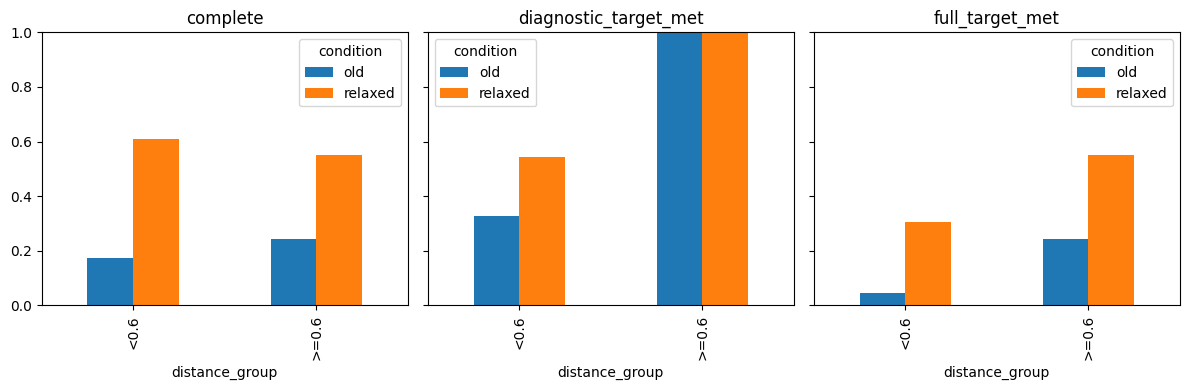

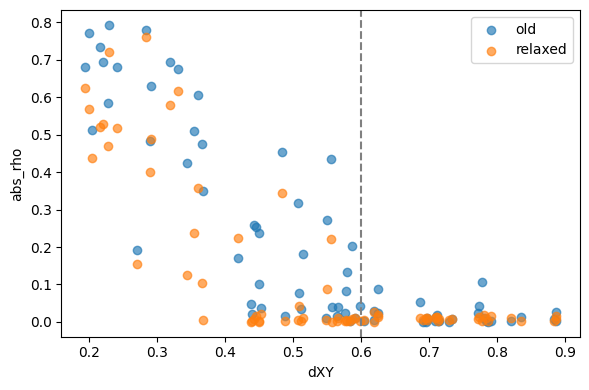

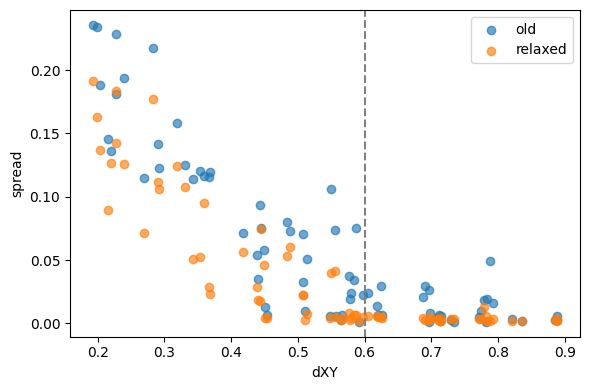

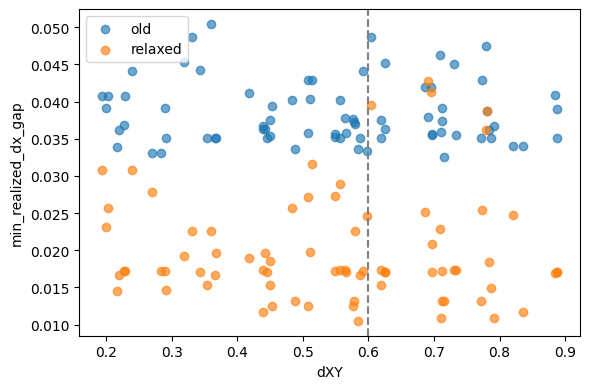

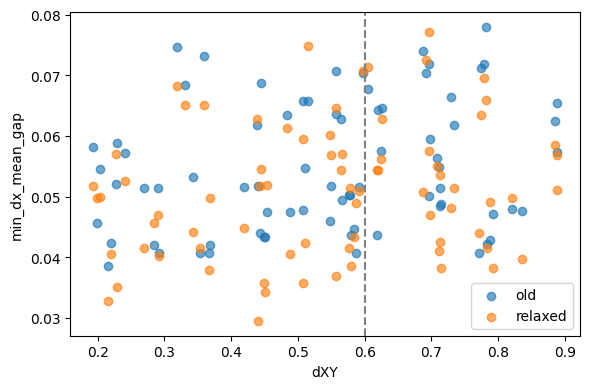

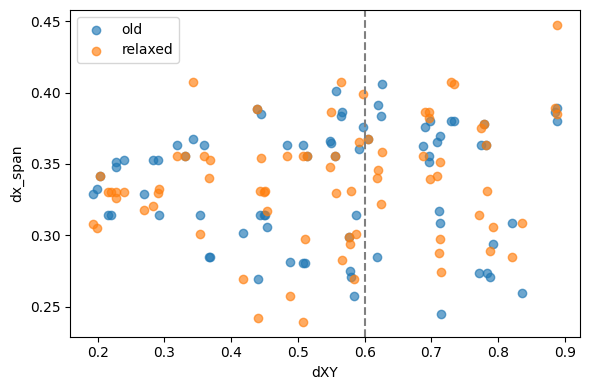

# Experiment E — integrated exploratory comparison

Same D pool, fixed centers, identical optimization budget, old vs relaxed bounds. No API generation.
- old / <0.6: 46 pairs, complete 8, diagnostics 15, full 2, mean |rho| 0.3215, spread 0.0902, min realized gap 0.0382
- old / >=0.6: 29 pairs, complete 7, diagnostics 29, full 7, mean |rho| 0.0173, spread 0.0112, min realized gap 0.0387
- relaxed / <0.6: 46 pairs, complete 28, diagnostics 25, full 14, mean |rho| 0.2012, spread 0.0577, min realized gap 0.0193
- relaxed / >=0.6: 29 pairs, complete 16, diagnostics 29, full 16, mean |rho| 0.0091, spread 0.0036, min realized gap 0.0211

Limits: shared five X, old-Y cue generation, partial semantic audit, heuristic joint search; threshold 0.6 is exploratory. Smaller gap can reduce actual distance separation. No formal adoption.
https://github.com/ryouy/GraduationThesis/tree/experiments/concept-pair-selection-v1/experiments/2026-11/1126_concept_pair_selection/results/20261126_concept_pair_int

In [7]:
def figsave(name,fig):
    buf=io.BytesIO();fig.savefig(buf,format='png',dpi=150,bbox_inches='tight');n='figures/'+name+'.png';put(n,buf.getvalue());outputs.append(n);plt.show();plt.close(fig)
fig,axs=plt.subplots(1,3,figsize=(12,4),sharey=True)
for ax,k in zip(axs,['complete','diagnostic_target_met','full_target_met']):
    j.groupby(['distance_group','condition'])[k].mean().unstack().plot.bar(ax=ax);ax.set_title(k);ax.set_ylim(0,1)
fig.tight_layout();figsave('success_rates',fig)
for k in ['abs_rho','spread','min_realized_dx_gap','min_dx_mean_gap','dx_span']:
    fig,ax=plt.subplots(figsize=(6,4))
    for cond,g in j.groupby('condition'):ax.scatter(g.distance_xy,g[k],label=cond,alpha=.65)
    ax.axvline(.6,ls='--',color='gray');ax.set(xlabel='dXY',ylabel=k);ax.legend();fig.tight_layout();figsave(k,fig)
report=['# Experiment E — integrated exploratory comparison','','Same D pool, fixed centers, identical optimization budget, old vs relaxed bounds. No API generation.']
for a in aggregate(j,['condition','distance_group']).itertuples():
    report.append(f'- {a.condition} / {a.distance_group}: {a.n_pairs} pairs, complete {a.complete}, diagnostics {a.diagnostic}, full {a.full}, mean |rho| {a.mean_abs_rho:.4f}, spread {a.mean_spread:.4f}, min realized gap {a.mean_min_realized_dx_gap:.4f}')
report+=['','Limits: shared five X, old-Y cue generation, partial semantic audit, heuristic joint search; threshold 0.6 is exploratory. Smaller gap can reduce actual distance separation. No formal adoption.']
put('analysis_summary.md',('\n'.join(report)+'\n').encode());outputs.append('analysis_summary.md')
manifest={'status':'complete_exploratory','config_sha256':sha(dump(config)),'n_primary':75,'n_anchors':5,'api_generation_calls':0,'files':{n:sha(get(n)) for n in outputs},'checkpoints':{pid:sha(get('checkpoints/'+pid+'.zip')) for pid in sorted(pairs.pair.unique())},'versions':{k:im.version(k) for k in ['numpy','pandas','scipy','matplotlib']}}
put('manifest.json',dump(manifest))
print('\n'.join(report));print('https://github.com/'+REPO+'/tree/'+BRANCH+'/'+DEST)

